In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    precision_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
from sklearn.ensemble import RandomForestClassifier

In [2]:
data=pd.read_csv("/content/customer_churn_cleaned.csv")

In [3]:
data.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group,charge_group
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12 months,low
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,25-48 months,medium
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12 months,medium
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25-48 months,medium
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12 months,high
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,0-12 months,high
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,No,13-24 months,high
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,Month-to-month,No,Mailed check,29.75,301.90,No,0-12 months,low
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,25-48 months,very high
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No,49-72 months,medium


In [4]:
print("Dataset shape: ", data.shape)
display(data.head())

Dataset shape:  (7043, 23)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group,charge_group
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12 months,low
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,25-48 months,medium
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12 months,medium
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25-48 months,medium
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12 months,high


In [5]:
print("Column names:")
print(data.columns.tolist())

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'tenure_group', 'charge_group']


In [6]:
print("Missing values:")
print(data.isnull().sum())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
tenure_group        0
charge_group        0
dtype: int64


In [7]:
print("Target Distribution:")
print(data['Churn'].value_counts())

Target Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [8]:
data=data.dropna()
data.shape

(7043, 23)

In [9]:
X=data.drop(columns=['Churn', 'customerID'])

In [10]:
X = X.drop(
    columns=["tenure_group", "charge_group"],
    errors="ignore"
)

In [11]:
y=data['Churn'].map({'No':0, 'Yes':1})

In [12]:
print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (7043, 19)
y Shape: (7043,)


In [13]:
print("Feature Columns:")
print(X.columns.tolist())

Feature Columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [14]:
print("Target Distribution:")
print(y.value_counts())

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [15]:
X_train, X_test, y_train, y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training Rows:", X_train.shape[0])
print("Testing Rows:", X_test.shape[0])

Training Rows: 5634
Testing Rows: 1409


In [16]:
numeric_features = X.select_dtypes(include=["int64","float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical_features:", numeric_features)
print("\nCategorical_features:", categorical_features)

Numerical_features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical_features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [17]:
numeric_transformer=Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer=Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor=ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])
print("Preprocessing pipeline created successfully")

Preprocessing pipeline created successfully


In [18]:
logistic_model=Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully")

Logistic Regression model trained successfully


In [19]:
y_pred=logistic_model.predict(X_test)
y_prob=logistic_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test,y_pred),4))
print("Precision:", round(precision_score(y_test,y_pred),4))
print("Recall:", round(recall_score(y_test,y_pred),4))
print("F1_Score:", round(f1_score(y_test, y_pred),4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob),4))

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

print("Confusion Matrix")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1_Score: 0.604
ROC-AUC: 0.8421
Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion Matrix
[[926 109]
 [165 209]]


In [20]:
rf_model= Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred=rf_model.predict(X_test)
rf_prob=rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Results")
print("---------------------")
print("Accuracy:", round(accuracy_score(y_test, rf_pred),4))
print("Precision:", round(precision_score(y_test, rf_pred),4))
print("Recall:", round(recall_score(y_test, rf_pred),4))
print("F1-score:", round(f1_score(y_test, rf_pred),4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob),4))

print("Classification Report:")
print(classification_report(
    y_test, rf_pred,
    target_names=["No Churn", "Churn"]
))

print("Confusion Matrix")
print(confusion_matrix(y_test, rf_pred))

Random Forest Results
---------------------
Accuracy: 0.7793
Precision: 0.5763
Recall: 0.6364
F1-score: 0.6048
ROC-AUC: 0.834
Classification Report:
              precision    recall  f1-score   support

    No Churn       0.86      0.83      0.85      1035
       Churn       0.58      0.64      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.73      1409
weighted avg       0.79      0.78      0.78      1409

Confusion Matrix
[[860 175]
 [136 238]]


Top 15 features influencing predictions:


,Feature,Importance
1,num__tenure,0.1279
3,num__TotalCharges,0.1248
2,num__MonthlyCharges,0.0998
36,cat__Contract_Month-to-month,0.0944
18,cat__OnlineSecurity_No,0.0479
38,cat__Contract_Two year,0.0452
27,cat__TechSupport_No,0.0389
16,cat__InternetService_Fiber optic,0.0366
43,cat__PaymentMethod_Electronic check,0.0314
21,cat__OnlineBackup_No,0.0175


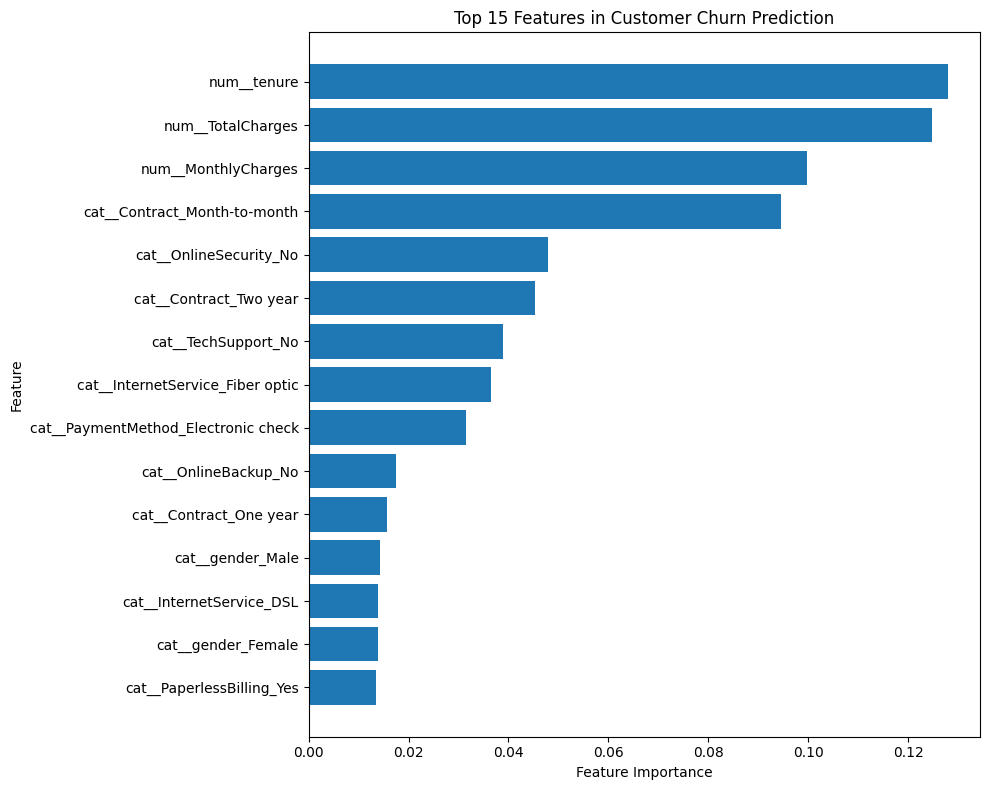

In [21]:
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

importances= rf_model.named_steps["classifier"].feature_importances_

importance_df=pd.DataFrame({
    "Feature":feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

print("Top 15 features influencing predictions:")
display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10,8))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features in Customer Churn Prediction")
plt.tight_layout()
plt.show()

In [22]:
print(X.columns.tolist())

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [23]:
rf_prob = rf_model.predict_proba(X_test)[:, 1]

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50]:
    pred = (rf_prob >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision_score(y_test, pred):.3f} | "
        f"Recall: {recall_score(y_test, pred):.3f} | "
        f"F1: {f1_score(y_test, pred):.3f}"
    )

Threshold: 0.30 | Precision: 0.485 | Recall: 0.834 | F1: 0.614
Threshold: 0.35 | Precision: 0.509 | Recall: 0.797 | F1: 0.621
Threshold: 0.40 | Precision: 0.532 | Recall: 0.749 | F1: 0.622
Threshold: 0.45 | Precision: 0.552 | Recall: 0.684 | F1: 0.611
Threshold: 0.50 | Precision: 0.576 | Recall: 0.636 | F1: 0.605


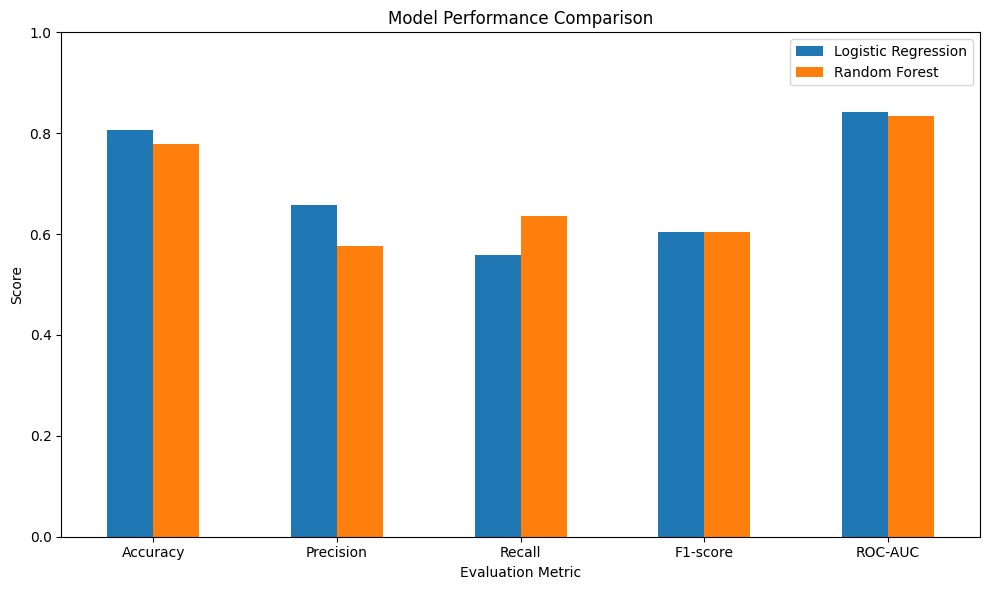

In [24]:
lr_pred = logistic_model.predict(X_test)
lr_prob = logistic_model.predict_proba(X_test)[:, 1]

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

lr_scores = [
    accuracy_score(y_test, lr_pred),
    precision_score(y_test, lr_pred),
    recall_score(y_test, lr_pred),
    f1_score(y_test, lr_pred),
    roc_auc_score(y_test, lr_prob)
]

rf_scores = [
    accuracy_score(y_test, rf_pred),
    precision_score(y_test, rf_pred),
    recall_score(y_test, rf_pred),
    f1_score(y_test, rf_pred),
    roc_auc_score(y_test, rf_prob)
]

results = pd.DataFrame({
    "Metric": metrics,
    "Logistic Regression": lr_scores,
    "Random Forest": rf_scores
})

results.set_index("Metric").plot(
    kind="bar", figsize=(10, 6), ylim=(0, 1), rot=0
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.legend()
plt.tight_layout()
plt.show()

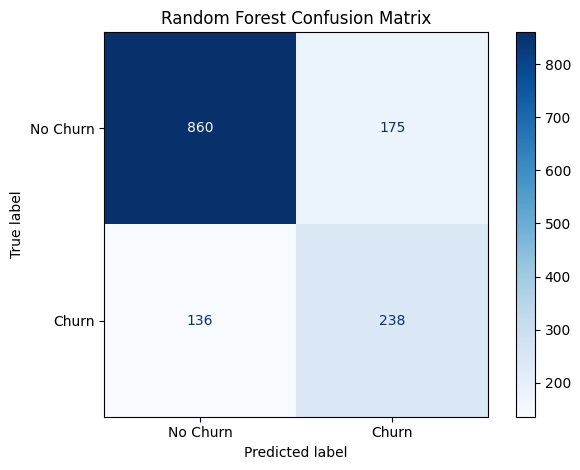

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

rf_pred = rf_model.predict(X_test)

cm = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

## Conclusion

In this project, I developed a machine learning solution to predict customer churn using the Telco Customer Churn dataset.

The dataset was preprocessed using a Scikit-learn pipeline, including missing-value handling, feature scaling, and one-hot encoding. Two classification algorithms were implemented: Logistic Regression and Random Forest.

The models were evaluated using Accuracy, Precision, Recall, F1-score, and ROC-AUC. Logistic Regression achieved better accuracy and ROC-AUC, while Random Forest showed higher recall, making it better at identifying customers who may churn.

The analysis highlighted important churn-related factors such as customer tenure, contract type, monthly charges, and support services.

This project helped me understand data preprocessing, classification models, model evaluation, and the practical application of machine learning to a business problem.